# Orders

## Load the dataset

In [1]:
from pathlib import Path
import os
import getpass
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

orders = pd.read_csv(r"D:\Users\User\Documents\Project_1\Data\olist_orders_dataset.csv")

## Overall view of data

In [2]:
print(orders.info())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
None


In [3]:
print(orders.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08

## Check for duplicates

In [4]:
# Check duplicate rows
orders.duplicated().sum()

np.int64(0)

In [5]:
# Check for duplicates in id column
orders['order_id'].duplicated().sum()

np.int64(0)

## Strigs to datetime conversion

In [6]:
# Changing dates in strings format to dates

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    # errors="coerce" turns blanks, spaces, and typos safely into NaT without crashing
    orders[column] = pd.to_datetime(orders[column], errors="coerce")


orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


## Check and handle missing values

In [7]:
# Check missing values
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

### Missing delivery to customer date 

In [8]:
# Filter for rows where the customer delivery date is blank (null) and count the order statuses for those blank rows
orders[orders['order_delivered_customer_date'].isna()]['order_status'].value_counts()

# 8 rows marked as delivered but are missing delivery dates (anomaly)

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [9]:
# Find the 8 rows that are marked 'delivered' but have no delivery date
delivered_but_no_date = orders[(orders['order_delivered_customer_date'].isna()) & (orders['order_status'] == 'delivered')]

delivered_but_no_date[['order_id','order_status','order_delivered_carrier_date',
                    'order_estimated_delivery_date','order_delivered_customer_date']]


,order_id,order_status,order_delivered_carrier_date,order_estimated_delivery_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-30 18:12:23,2017-12-18,NaT
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-25 08:05:00,2018-07-16,NaT
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-03 13:57:00,2018-07-30,NaT
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-03 13:57:00,2018-07-30,NaT
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-03 09:28:00,2018-07-24,NaT
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,NaT,2017-06-23,NaT
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-12 14:10:00,2018-06-26,NaT
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-07-03 19:26:00,2018-07-19,NaT


### Missing payment approval date

In [10]:
# Filter for rows where order_approved_at (payment aprroved date) is missing and count by status
# 160 rows have blanks for payment approval timestamp
orders[orders['order_approved_at'].isna()]['order_status'].value_counts()


# 14 rows are delivered but no payment approval date which is IMPOSSIBLE because an order cannot be shipped and delivered without payment
# 141 rows from cancelled = customer cancelled the order before payment approval
# 5 rows from created = order was placed but buyer hasn't paid yet or card authorization is still pending


order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

In [11]:
# Find the 14 rows that are marked 'delivered' but have no payment approval date
delivered_but_no_approval = orders[(orders['order_approved_at'].isna()) & (orders['order_status'] == 'delivered')]

delivered_but_no_approval[['order_id','order_status','order_delivered_carrier_date',
                    'order_estimated_delivery_date','order_delivered_customer_date','order_approved_at']]

,order_id,order_status,order_delivered_carrier_date,order_estimated_delivery_date,order_delivered_customer_date,order_approved_at
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,2017-02-23 12:04:47,2017-03-17,2017-03-01 13:25:33,NaT
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,2017-02-23 09:01:52,2017-03-21,2017-03-02 10:05:06,NaT
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,2017-02-22 16:25:25,2017-03-17,2017-03-01 08:07:38,NaT
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,2017-02-22 11:23:10,2017-03-31,2017-03-09 07:28:47,NaT
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,2017-02-22 11:23:11,2017-03-20,2017-03-02 11:09:19,NaT
26800,c1d4211b3dae76144deccd6c74144a88,delivered,2017-01-25 14:56:50,2017-03-01,2017-01-30 18:16:01,NaT
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,2017-02-23 03:11:48,2017-03-27,2017-03-02 03:41:58,NaT
39334,d77031d6a3c8a52f019764e68f211c69,delivered,2017-02-23 07:23:36,2017-03-22,2017-03-02 16:15:23,NaT
48401,7002a78c79c519ac54022d4f8a65e6e8,delivered,2017-01-27 11:08:05,2017-03-16,2017-02-06 14:22:19,NaT
61743,2eecb0d85f281280f79fa00f9cec1a95,delivered,2017-02-22 11:42:51,2017-03-20,2017-03-03 12:16:03,NaT


### Missing delivery to carrier date

In [12]:
# Filter for rows where order_delivered_carrier_date is missing and count by status
# 1783 rows have blanks for handing to logistic partner timestamp
# These represent orders that never made it to the logistics stage. This happens if the order was canceled right after payment or is still currently being processed by the seller.
orders[orders['order_delivered_carrier_date'].isna()]['order_status'].value_counts()


# unavailable and canceled = these orders were out of stock or canceled before they could be shipped
# invoiced and processing = these are active orders, seller has billed the customer or is currently packing the items but haven't handed the item over to logistics yet
# created and approved = these are in the very early stages of the sales funnel, awaiting payment validation or processing
# delivered (anomaly) = an order cannot be succesfully delivered to a customer's house if it was never handed over to the carrier in the first place

order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

In [13]:
# Find the 2 rows that are marked 'delivered' but have no delivered to carrier date
delivered_but_no_carrier_date = orders[(orders['order_delivered_carrier_date'].isna()) & (orders['order_status'] == 'delivered')]

delivered_but_no_carrier_date[['order_id','order_status','order_delivered_carrier_date',
                    'order_estimated_delivery_date','order_delivered_customer_date','order_approved_at']]

,order_id,order_status,order_delivered_carrier_date,order_estimated_delivery_date,order_delivered_customer_date,order_approved_at
73222,2aa91108853cecb43c84a5dc5b277475,delivered,NaT,2017-11-14,2017-11-20 19:44:47,2017-09-29 09:07:16
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,NaT,2017-06-23,NaT,2017-05-25 23:30:16


## Delivery time (days) calculation

In [14]:
# Strip hours/minutes from all three dates before taking difference
# dt.normalize set the time part to midnight (00:00:00) so that we are comparing calendar dates rather than exact timestamps, guarantee accuracte day to day comparison
orders['purchase_date'] = orders['order_purchase_timestamp'].dt.normalize()
orders['delivery_date'] = orders['order_delivered_customer_date'].dt.normalize()


# Calculate number of days needed for the item to be delivered
# dt.days = takes only the day and strips away the hours, minutes and seconds
# output will be float if there are blanks (because we have missing delivery dates)
orders['days_to_deliver'] = (orders['delivery_date'] - orders['purchase_date']).dt.days
print(orders['days_to_deliver'])

0         8.0
1        14.0
2         9.0
3        14.0
4         3.0
         ... 
99436     8.0
99437    22.0
99438    25.0
99439    17.0
99440     8.0
Name: days_to_deliver, Length: 99441, dtype: float64


In [15]:
# Check if there are any negative delivery times (impossible because an order cannot be delivered before it is purchased)
len(orders[orders["days_to_deliver"] < 0])

0

In [16]:
# Turns floats into integers, but leaves blanks as <NA> instead of crashing
orders['days_to_deliver'] = orders['days_to_deliver'].astype('Int64')
print("Current data type:", orders['days_to_deliver'].dtype)
print(orders['days_to_deliver'])

Current data type: Int64
0         8
1        14
2         9
3        14
4         3
         ..
99436     8
99437    22
99438    25
99439    17
99440     8
Name: days_to_deliver, Length: 99441, dtype: Int64


## Estimated delivery time (days) calculation

In [17]:
# Strip hours/minutes from the estimated delivery date before taking the difference
orders['estimated_delivery_date'] = orders['order_estimated_delivery_date'].dt.normalize()

# Calculate how long (number of days) the customers were expected to wait
# no blanks in estimated delivery date and purchase timestamp so output is integer
orders["days_to_estimate_delivery"] = (orders["estimated_delivery_date"] - orders["purchase_date"]).dt.days
print(orders['days_to_estimate_delivery'])


0        16
1        20
2        27
3        27
4        13
         ..
99436    19
99437    24
99438    31
99439    38
99440    26
Name: days_to_estimate_delivery, Length: 99441, dtype: int64


## Delivery timing indicator

In [18]:
import numpy as np

# Define the conditional logic (order matters: top to bottom)
conditions = [
   (orders["delivery_date"].isna()) & (orders["order_status"] == "delivered"),   # Rule 1: delivered status but no delivery date
   (orders["order_status"] == "canceled") & (orders["delivery_date"].notna()),    # Rule 2: canceled but has delivery date
   (orders["delivery_date"].isna()) & (orders["order_status"] != "delivered"),  # Rule 3: not delivered status and no delivery date
   (orders["delivery_date"] > orders["estimated_delivery_date"]) & (orders["order_status"] == "delivered"),                   # Rule 4: Delivered late
   (orders["delivery_date"] < orders["estimated_delivery_date"]) & (orders["order_status"] == "delivered"),                 # Rule 5: Delivered early
   (orders["order_status"] == "delivered") & (orders["delivery_date"] == orders["estimated_delivery_date"])   # Rule 6: Delivered on time
]

# Define corresponding labels
# But have to BE CAREFUL because there are few rows that are delivered but have no delivery date
choice_list = ["Delivered (No Date)","Canceled (With Date)", "Not Delivered", "Late", "Early","On Time"]

# Apply status (anything else defaults to "On Time")
orders["delivery_status"] = np.select(conditions, choice_list, default="Others")

In [19]:
orders["delivery_status"].value_counts()

delivery_status
Early                   88644
Late                     6534
Not Delivered            2957
On Time                  1292
Delivered (No Date)         8
Canceled (With Date)        6
Name: count, dtype: int64

In [20]:
# Filter Delivered (No Date) rows AND select specific columns
orders.loc[
    orders["delivery_status"] == "Delivered (No Date)",
    ['delivery_status','order_status','order_purchase_timestamp','purchase_date','order_delivered_customer_date','delivery_date',
     'days_to_deliver','order_estimated_delivery_date','estimated_delivery_date','days_to_estimate_delivery']
]

,delivery_status,order_status,order_purchase_timestamp,purchase_date,order_delivered_customer_date,delivery_date,days_to_deliver,order_estimated_delivery_date,estimated_delivery_date,days_to_estimate_delivery
3002,Delivered (No Date),delivered,2017-11-28 17:44:07,2017-11-28,NaT,NaT,<NA>,2017-12-18,2017-12-18,20
20618,Delivered (No Date),delivered,2018-06-20 06:58:43,2018-06-20,NaT,NaT,<NA>,2018-07-16,2018-07-16,26
43834,Delivered (No Date),delivered,2018-07-01 17:05:11,2018-07-01,NaT,NaT,<NA>,2018-07-30,2018-07-30,29
79263,Delivered (No Date),delivered,2018-07-01 22:05:55,2018-07-01,NaT,NaT,<NA>,2018-07-30,2018-07-30,29
82868,Delivered (No Date),delivered,2018-07-01 21:14:02,2018-07-01,NaT,NaT,<NA>,2018-07-24,2018-07-24,23
92643,Delivered (No Date),delivered,2017-05-25 23:22:43,2017-05-25,NaT,NaT,<NA>,2017-06-23,2017-06-23,29
97647,Delivered (No Date),delivered,2018-06-08 12:09:39,2018-06-08,NaT,NaT,<NA>,2018-06-26,2018-06-26,18
98038,Delivered (No Date),delivered,2018-06-27 16:09:12,2018-06-27,NaT,NaT,<NA>,2018-07-19,2018-07-19,22


In [21]:
# Filter ON-TIME rows AND select specific columns
orders.loc[
    orders["delivery_status"] == "On Time",
    ['delivery_status','order_purchase_timestamp','purchase_date','order_delivered_customer_date','delivery_date',
     'days_to_deliver','order_estimated_delivery_date','estimated_delivery_date','days_to_estimate_delivery']
]

,delivery_status,order_purchase_timestamp,purchase_date,order_delivered_customer_date,delivery_date,days_to_deliver,order_estimated_delivery_date,estimated_delivery_date,days_to_estimate_delivery
35,On Time,2018-02-17 15:59:46,2018-02-17,2018-03-20 00:59:25,2018-03-20,31,2018-03-20,2018-03-20,31
152,On Time,2018-02-14 13:05:17,2018-02-14,2018-03-09 21:52:36,2018-03-09,23,2018-03-09,2018-03-09,23
226,On Time,2018-08-08 21:11:25,2018-08-08,2018-08-15 15:02:09,2018-08-15,7,2018-08-15,2018-08-15,7
269,On Time,2018-01-22 19:22:26,2018-01-22,2018-02-06 15:49:01,2018-02-06,15,2018-02-06,2018-02-06,15
357,On Time,2017-05-08 12:22:44,2017-05-08,2017-05-19 15:55:47,2017-05-19,11,2017-05-19,2017-05-19,11
...,...,...,...,...,...,...,...,...,...
98914,On Time,2017-05-13 23:45:23,2017-05-13,2017-06-02 11:28:09,2017-06-02,20,2017-06-02,2017-06-02,20
99005,On Time,2017-04-23 12:07:48,2017-04-23,2017-05-16 14:33:34,2017-05-16,23,2017-05-16,2017-05-16,23
99032,On Time,2017-11-25 20:28:22,2017-11-25,2017-12-19 14:47:05,2017-12-19,24,2017-12-19,2017-12-19,24
99116,On Time,2018-01-29 15:19:13,2018-01-29,2018-02-21 17:46:45,2018-02-21,23,2018-02-21,2018-02-21,23


In [22]:
# Validate if all On Time rows have the same number of days to deliver as the estimated days to deliver

on_time_check = orders[
    orders["delivery_status"] == "On Time"
]

print(
    (on_time_check["days_to_deliver"] !=
     on_time_check["days_to_estimate_delivery"]).sum()
)

0


In [23]:
# Filter NOT DELIVERED rows AND select specific columns
orders.loc[
    orders["delivery_status"] == "Not Delivered",
    ['delivery_status','order_status','order_purchase_timestamp','purchase_date','order_delivered_customer_date','delivery_date',
     'days_to_deliver','order_estimated_delivery_date','estimated_delivery_date','days_to_estimate_delivery']
]

,delivery_status,order_status,order_purchase_timestamp,purchase_date,order_delivered_customer_date,delivery_date,days_to_deliver,order_estimated_delivery_date,estimated_delivery_date,days_to_estimate_delivery
6,Not Delivered,invoiced,2017-04-11 12:22:08,2017-04-11,NaT,NaT,<NA>,2017-05-09,2017-05-09,28
44,Not Delivered,shipped,2018-06-04 16:44:48,2018-06-04,NaT,NaT,<NA>,2018-06-28,2018-06-28,24
103,Not Delivered,invoiced,2018-08-03 17:44:42,2018-08-03,NaT,NaT,<NA>,2018-08-21,2018-08-21,18
128,Not Delivered,processing,2017-09-03 14:22:03,2017-09-03,NaT,NaT,<NA>,2017-10-03,2017-10-03,30
154,Not Delivered,shipped,2018-01-10 11:33:07,2018-01-10,NaT,NaT,<NA>,2018-02-07,2018-02-07,28
...,...,...,...,...,...,...,...,...,...,...
99283,Not Delivered,canceled,2018-08-31 16:13:44,2018-08-31,NaT,NaT,<NA>,2018-10-01,2018-10-01,31
99313,Not Delivered,processing,2018-01-05 23:07:24,2018-01-05,NaT,NaT,<NA>,2018-02-06,2018-02-06,32
99347,Not Delivered,canceled,2018-09-06 18:45:47,2018-09-06,NaT,NaT,<NA>,2018-09-27,2018-09-27,21
99348,Not Delivered,unavailable,2017-08-23 16:28:04,2017-08-23,NaT,NaT,<NA>,2017-09-15,2017-09-15,23


In [24]:
# Filter EARLY rows AND select specific columns
orders.loc[
    orders["delivery_status"] == "Early",
    ['delivery_status','order_purchase_timestamp','purchase_date','order_delivered_customer_date','delivery_date',
     'days_to_deliver','order_estimated_delivery_date','estimated_delivery_date','days_to_estimate_delivery']
]

,delivery_status,order_purchase_timestamp,purchase_date,order_delivered_customer_date,delivery_date,days_to_deliver,order_estimated_delivery_date,estimated_delivery_date,days_to_estimate_delivery
0,Early,2017-10-02 10:56:33,2017-10-02,2017-10-10 21:25:13,2017-10-10,8,2017-10-18,2017-10-18,16
1,Early,2018-07-24 20:41:37,2018-07-24,2018-08-07 15:27:45,2018-08-07,14,2018-08-13,2018-08-13,20
2,Early,2018-08-08 08:38:49,2018-08-08,2018-08-17 18:06:29,2018-08-17,9,2018-09-04,2018-09-04,27
3,Early,2017-11-18 19:28:06,2017-11-18,2017-12-02 00:28:42,2017-12-02,14,2017-12-15,2017-12-15,27
4,Early,2018-02-13 21:18:39,2018-02-13,2018-02-16 18:17:02,2018-02-16,3,2018-02-26,2018-02-26,13
...,...,...,...,...,...,...,...,...,...
99436,Early,2017-03-09 09:54:05,2017-03-09,2017-03-17 15:08:01,2017-03-17,8,2017-03-28,2017-03-28,19
99437,Early,2018-02-06 12:58:58,2018-02-06,2018-02-28 17:37:56,2018-02-28,22,2018-03-02,2018-03-02,24
99438,Early,2017-08-27 14:46:43,2017-08-27,2017-09-21 11:24:17,2017-09-21,25,2017-09-27,2017-09-27,31
99439,Early,2018-01-08 21:28:27,2018-01-08,2018-01-25 23:32:54,2018-01-25,17,2018-02-15,2018-02-15,38


In [25]:
# Filter LATE rows AND select specific columns
orders.loc[
    orders["delivery_status"] == "Late",
    ['delivery_status','order_purchase_timestamp','purchase_date','order_delivered_customer_date','delivery_date',
     'days_to_deliver','order_estimated_delivery_date','estimated_delivery_date','days_to_estimate_delivery']
]

,delivery_status,order_purchase_timestamp,purchase_date,order_delivered_customer_date,delivery_date,days_to_deliver,order_estimated_delivery_date,estimated_delivery_date,days_to_estimate_delivery
20,Late,2017-09-18 14:31:30,2017-09-18,2017-10-09 22:23:46,2017-10-09,21,2017-09-28,2017-09-28,10
25,Late,2018-02-20 23:46:53,2018-02-20,2018-03-21 22:03:54,2018-03-21,29,2018-03-12,2018-03-12,20
41,Late,2017-11-24 21:27:48,2017-11-24,2017-12-28 18:59:23,2017-12-28,34,2017-12-21,2017-12-21,27
57,Late,2018-03-09 14:50:15,2018-03-09,2018-04-03 13:28:46,2018-04-03,25,2018-04-02,2018-04-02,24
58,Late,2017-03-13 18:14:36,2017-03-13,2017-04-06 13:37:16,2017-04-06,24,2017-03-30,2017-03-30,17
...,...,...,...,...,...,...,...,...,...
99396,Late,2018-08-02 22:46:54,2018-08-02,2018-08-21 00:03:26,2018-08-21,19,2018-08-16,2018-08-16,14
99397,Late,2018-03-13 21:48:57,2018-03-13,2018-04-05 19:59:49,2018-04-05,23,2018-04-02,2018-04-02,20
99423,Late,2017-10-12 20:54:11,2017-10-12,2017-11-21 17:06:59,2017-11-21,40,2017-10-31,2017-10-31,19
99425,Late,2018-03-21 19:47:18,2018-03-21,2018-04-11 00:48:31,2018-04-11,21,2018-04-09,2018-04-09,19


In [26]:
# Filter CANCELED rows AND select specific columns
orders.loc[
    orders["delivery_status"] == "Canceled (With Date)",
    ['delivery_status','order_purchase_timestamp','purchase_date','order_delivered_customer_date','delivery_date',
     'days_to_deliver','order_estimated_delivery_date','estimated_delivery_date','days_to_estimate_delivery']
]

,delivery_status,order_purchase_timestamp,purchase_date,order_delivered_customer_date,delivery_date,days_to_deliver,order_estimated_delivery_date,estimated_delivery_date,days_to_estimate_delivery
2921,Canceled (With Date),2018-02-19 19:48:52,2018-02-19,2018-03-21 22:03:51,2018-03-21,30,2018-03-09,2018-03-09,18
8791,Canceled (With Date),2016-10-09 00:56:52,2016-10-09,2016-10-16 14:36:59,2016-10-16,7,2016-11-30,2016-11-30,52
58266,Canceled (With Date),2016-10-07 14:52:30,2016-10-07,2016-10-14 15:07:11,2016-10-14,7,2016-11-29,2016-11-29,53
59332,Canceled (With Date),2016-10-08 20:17:50,2016-10-08,2016-10-19 18:47:43,2016-10-19,11,2016-11-30,2016-11-30,53
92636,Canceled (With Date),2016-10-03 21:01:41,2016-10-03,2016-11-08 10:58:34,2016-11-08,36,2016-11-25,2016-11-25,53
94399,Canceled (With Date),2016-10-09 15:39:56,2016-10-09,2016-11-09 14:53:50,2016-11-09,31,2016-12-08,2016-12-08,60


## EDA

### Purchase time period of dataset

In [27]:
# Find the earliest purchase

print(
    "Earliest purchase:",
    orders["order_purchase_timestamp"].min()
)

# Find the latest purchase
print(
    "Latest purchase:",
    orders["order_purchase_timestamp"].max()
)

Earliest purchase: 2016-09-04 21:15:19
Latest purchase: 2018-10-17 17:30:18


### Number of orders by month

In [28]:
# Create a new column that contains the year and month of purchase for each order (e.g. 2018-02)
orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

# should use 2017 to 2018 Aug for monthly trend analysis
# Count orders for each month
# Without sort_index(), the output will be sorted by the number of orders in descending order.
# With sort_index(), the output will be sorted by month in ascending order.
orders["purchase_month"].value_counts().sort_index()

purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

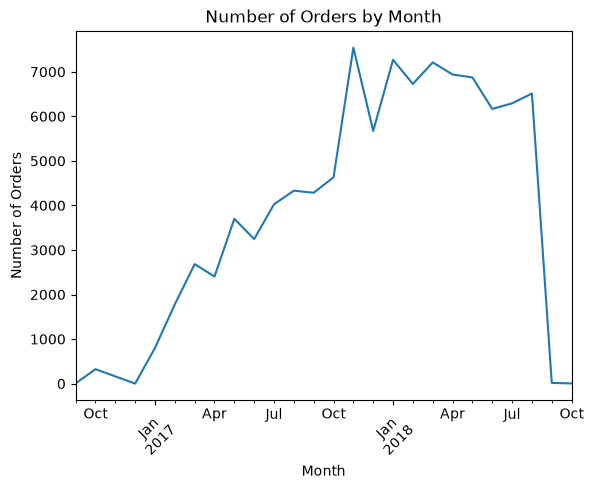

In [29]:
import matplotlib.pyplot as plt

# Take the monthly order counts and plot them as a line chart to visualize the trend over time

orders["purchase_month"].value_counts().sort_index().plot(
    kind="line"
)

plt.title("Number of Orders by Month")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

In [30]:
# See the orders that were purchased in September and October 2018 because these are the months with the lowest number of orders
orders[
    orders["purchase_month"].isin(
        [pd.Period("2016-09"),pd.Period("2016-12"),pd.Period("2018-09"), pd.Period("2018-10")]
    )
][[
    "order_id",
    "order_purchase_timestamp",
    "order_status",
    "order_delivered_customer_date",
]]

,order_id,order_purchase_timestamp,order_status,order_delivered_customer_date
1801,ed3efbd3a87bea76c2812c66a0b32219,2018-09-20 13:54:16,canceled,NaT
4396,e5fa5a7210941f7d56d0208e4e071d35,2016-09-05 00:15:34,canceled,NaT
4541,2e7a8482f6fb09756ca50c10d7bfc047,2016-09-04 21:15:19,shipped,NaT
5149,ea844c92cf978ea23321fa7fe5871761,2018-09-13 09:56:12,canceled,NaT
9976,87ae60ef8b08ae0e5f903cacb53a6904,2018-09-11 16:45:54,canceled,NaT
10071,809a282bbd5dbcabb6f2f724fca862ec,2016-09-13 15:24:19,canceled,NaT
16366,bd35b677fd239386e9861d11ae98ab56,2018-09-17 17:21:16,canceled,NaT
20778,4d59cc2a2e7bb6c0a851725f5888a9b5,2018-09-06 14:50:07,canceled,NaT
24410,0d3adebce4bebc1f80a7f36e9833f497,2018-09-03 18:40:50,canceled,NaT
30710,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,delivered,2016-11-09 07:47:38


### Distribution of order status

In [31]:
# Check order status
# unavailable = due to product out of stock or could not be sourced from seller
# created/approved = placed order and payment is approved
# invoiced = seller has generated invoice and sent the bill to customer but the item has not been packed, shipped or handed to a carrier
# processing = warehouse workers are picking, packing and boxing the item
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

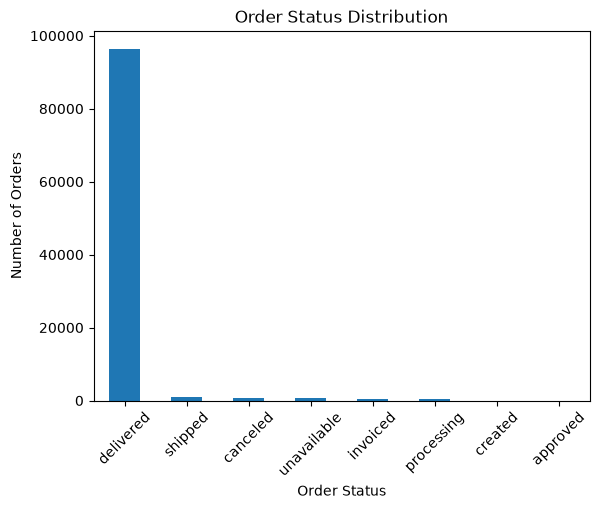

In [32]:
import matplotlib.pyplot as plt

# Visualise order status

orders["order_status"].value_counts().plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

### Crosstabs of delivered to customer dates with order status

In [33]:
# Compare missing delivery dates with order status

pd.crosstab(
    orders["order_status"],
    orders["order_delivered_customer_date"].isna()
)

# Anomaly = 6 orders that are cancelled but has a delivery date

order_delivered_customer_date,False,True
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


In [34]:
canceled_with_delivery = orders[
    (orders["order_status"] == "canceled") &
    (orders["order_delivered_customer_date"].notna())
]

canceled_with_delivery

# The customer likely requested a cancellation because the package was taking too long to arrive.
# However, because the item was already deep inside the carrier's logistics network, it couldn't be stopped, and the delivery driver completed the drop-off anyway.
# Even though they arrived, the customer was likely refunded since the official status is marked as canceled.

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_date,delivery_date,days_to_deliver,estimated_delivery_date,days_to_estimate_delivery,delivery_status,purchase_month
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09,2018-02-19,2018-03-21,30,2018-03-09,18,Canceled (With Date),2018-02
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30,2016-10-09,2016-10-16,7,2016-11-30,52,Canceled (With Date),2016-10
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29,2016-10-07,2016-10-14,7,2016-11-29,53,Canceled (With Date),2016-10
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30,2016-10-08,2016-10-19,11,2016-11-30,53,Canceled (With Date),2016-10
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25,2016-10-03,2016-11-08,36,2016-11-25,53,Canceled (With Date),2016-10
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08,2016-10-09,2016-11-09,31,2016-12-08,60,Canceled (With Date),2016-10


### Crosstabs of delivered to carrier dates with order status

In [35]:
# Compare missing delivery dates to carrier with order status
# 75 canceled orders have carrier dates, which may happen because the order is canceled after the item is handed to the carrier

pd.crosstab(
    orders["order_status"],
    orders["order_delivered_carrier_date"].isna()
)

order_delivered_carrier_date,False,True
order_status,,
approved,0,2
canceled,75,550
created,0,5
delivered,96476,2
invoiced,0,314
processing,0,301
shipped,1107,0
unavailable,0,609


### Crosstabs of purchase timestamp with order status

In [36]:
# Compare missing purchase timestamps with order status
# every order should have a purchase timestamp because it means the order entered the system
# for unavailable = payment approved but order couldn't be fulfilled due to stock issues, so the order was canceled and refunded. This is normal and expected behavior.

pd.crosstab(
    orders["order_status"],
    orders["order_purchase_timestamp"].isna()
)

order_purchase_timestamp,False
order_status,
approved,2
canceled,625
created,5
delivered,96478
invoiced,314
processing,301
shipped,1107
unavailable,609


### Crosstabs of payment approval dates with order status

In [37]:
# Compare missing delivery dates with order status
# Unavailable orders were approved but the seller could not source the product from their suppliers, so the order was never shipped and delivered to the customer. The customer was likely refunded.

pd.crosstab(
    orders["order_status"],
    orders["order_approved_at"].isna())

order_approved_at,False,True
order_status,,
approved,2,0
canceled,484,141
created,0,5
delivered,96464,14
invoiced,314,0
processing,301,0
shipped,1107,0
unavailable,609,0


In [38]:
# order is canceled because the customer canceled the order before payment approval, so there is no payment approval timestamp. This is normal and expected behavior.
canceled_no_approval = orders[(orders["order_status"] == "canceled") & (orders["order_approved_at"].isna())]

canceled_no_approval

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_date,delivery_date,days_to_deliver,estimated_delivery_date,days_to_estimate_delivery,delivery_status,purchase_month
1130,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaT,NaT,NaT,2018-09-12,2018-08-28,NaT,<NA>,2018-09-12,15,Not Delivered,2018-08
1801,ed3efbd3a87bea76c2812c66a0b32219,191984a8ba4cbb2145acb4fe35b69664,canceled,2018-09-20 13:54:16,NaT,NaT,NaT,2018-10-17,2018-09-20,NaT,<NA>,2018-10-17,27,Not Delivered,2018-09
1868,df8282afe61008dc26c6c31011474d02,aa797b187b5466bc6925aaaa4bb3bed1,canceled,2017-03-04 12:14:30,NaT,NaT,NaT,2017-04-10,2017-03-04,NaT,<NA>,2017-04-10,37,Not Delivered,2017-03
2029,8d4c637f1accf7a88a4555f02741e606,b1dd715db389a2077f43174e7a675d07,canceled,2018-08-29 16:27:49,NaT,NaT,NaT,2018-09-13,2018-08-29,NaT,<NA>,2018-09-13,15,Not Delivered,2018-08
2161,7a9d4c7f9b068337875b95465330f2fc,7f71ae48074c0cfec9195f88fcbfac55,canceled,2017-05-01 16:12:39,NaT,NaT,NaT,2017-05-30,2017-05-01,NaT,<NA>,2017-05-30,29,Not Delivered,2017-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97696,5a00b4d35edffc56b825c3646a99ba9d,6a3bdf004ca96338fb5fad1b8d93c2e6,canceled,2017-07-02 15:38:46,NaT,NaT,NaT,2017-07-25,2017-07-02,NaT,<NA>,2017-07-25,23,Not Delivered,2017-07
98415,227c804e2a44760671a6a5697ea549e4,62e7477e75e542243ee62a0ba73f410f,canceled,2017-09-28 15:02:56,NaT,NaT,NaT,2017-10-16,2017-09-28,NaT,<NA>,2017-10-16,18,Not Delivered,2017-09
98909,e49e7ce1471b4693482d40c2bd3ad196,e4e7ab3f449aeb401f0216f86c2104db,canceled,2018-08-07 11:16:28,NaT,NaT,NaT,2018-08-10,2018-08-07,NaT,<NA>,2018-08-10,3,Not Delivered,2018-08
99283,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaT,NaT,NaT,2018-10-01,2018-08-31,NaT,<NA>,2018-10-01,31,Not Delivered,2018-08


In [39]:
canceled_but_approved = orders[(orders["order_status"] == "canceled") & (orders["order_approved_at"].notna())]

canceled_but_approved
# Check whether canceled but approved orders progressed to shipping or delivery
print(canceled_but_approved[["order_delivered_carrier_date", "order_delivered_customer_date"]].notna().sum())

order_delivered_carrier_date     75
order_delivered_customer_date     6
dtype: int64


In [40]:
unavailable_but_approved = orders[(orders["order_status"] == "unavailable") & (orders["order_approved_at"].notna())]

unavailable_but_approved

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_date,delivery_date,days_to_deliver,estimated_delivery_date,days_to_estimate_delivery,delivery_status,purchase_month
266,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaT,NaT,2017-12-05,2017-11-16,NaT,<NA>,2017-12-05,19,Not Delivered,2017-11
586,c272bcd21c287498b4883c7512019702,9582c5bbecc65eb568e2c1d839b5cba1,unavailable,2018-01-31 11:31:37,2018-01-31 14:23:50,NaT,NaT,2018-02-16,2018-01-31,NaT,<NA>,2018-02-16,16,Not Delivered,2018-01
687,37553832a3a89c9b2db59701c357ca67,7607cd563696c27ede287e515812d528,unavailable,2017-08-14 17:38:02,2017-08-17 00:15:18,NaT,NaT,2017-09-05,2017-08-14,NaT,<NA>,2017-09-05,22,Not Delivered,2017-08
737,d57e15fb07fd180f06ab3926b39edcd2,470b93b3f1cde85550fc74cd3a476c78,unavailable,2018-01-08 19:39:03,2018-01-09 07:26:08,NaT,NaT,2018-02-06,2018-01-08,NaT,<NA>,2018-02-06,29,Not Delivered,2018-01
1160,2f634e2cebf8c0283e7ef0989f77d217,7353b0fb8e8d9675e3a704c60ca44ebe,unavailable,2017-09-27 20:55:33,2017-09-28 01:32:50,NaT,NaT,2017-10-27,2017-09-27,NaT,<NA>,2017-10-27,30,Not Delivered,2017-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99147,6cf5c427fb11bc5fe8abefa86aa7ba0b,91ac14a1e50bc022eeecf0c2ba37006a,unavailable,2017-10-17 10:53:48,2017-10-19 03:12:43,NaT,NaT,2017-10-27,2017-10-17,NaT,<NA>,2017-10-27,10,Not Delivered,2017-10
99233,1c7c8ab324927f5b6e52338bd110bef4,95b1767df51d6fa09402267d8de314df,unavailable,2017-12-23 18:48:09,2017-12-23 18:54:22,NaT,NaT,2018-01-19,2017-12-23,NaT,<NA>,2018-01-19,27,Not Delivered,2017-12
99252,aaab15da689073f8f9aa978a390a69d1,df20748206e4b865b2f14a5eabbfcf34,unavailable,2018-01-16 14:27:59,2018-01-17 03:37:34,NaT,NaT,2018-02-06,2018-01-16,NaT,<NA>,2018-02-06,21,Not Delivered,2018-01
99348,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaT,NaT,2017-09-15,2017-08-23,NaT,<NA>,2017-09-15,23,Not Delivered,2017-08


In [41]:
# its normal that the approved orders have a payment approval date, but the order is still at approved, so maybe stuck in the pipeline
approved = orders[(orders["order_status"] == "approved") & (orders["order_approved_at"].notna())]

approved

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_date,delivery_date,days_to_deliver,estimated_delivery_date,days_to_estimate_delivery,delivery_status,purchase_month
44897,a2e4c44360b4a57bdff22f3a4630c173,8886130db0ea6e9e70ba0b03d7c0d286,approved,2017-02-06 20:18:17,2017-02-06 20:30:19,NaT,NaT,2017-03-01,2017-02-06,NaT,<NA>,2017-03-01,23,Not Delivered,2017-02
88457,132f1e724165a07f6362532bfb97486e,b2191912d8ad6eac2e4dc3b6e1459515,approved,2017-04-25 01:25:34,2017-04-30 20:32:41,NaT,NaT,2017-05-22,2017-04-25,NaT,<NA>,2017-05-22,27,Not Delivered,2017-04


### Distribution of delivery days

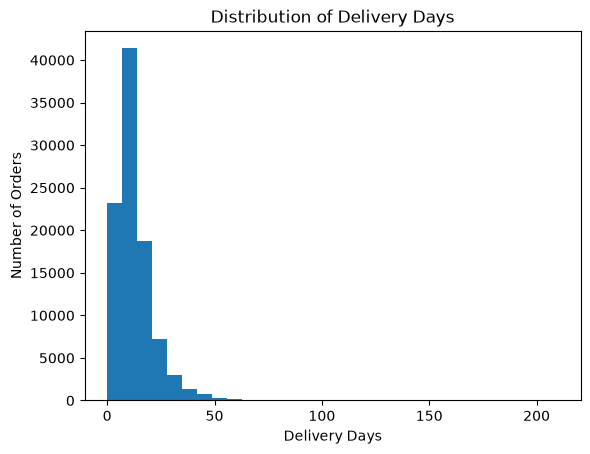

In [42]:
# Explore how long do orders usually take to be delivered

orders["days_to_deliver"].plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Delivery Days")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")
# Zoom in on the main distribution area
#plt.xlim(0, 60)
plt.show()


### Distribution of delivery status

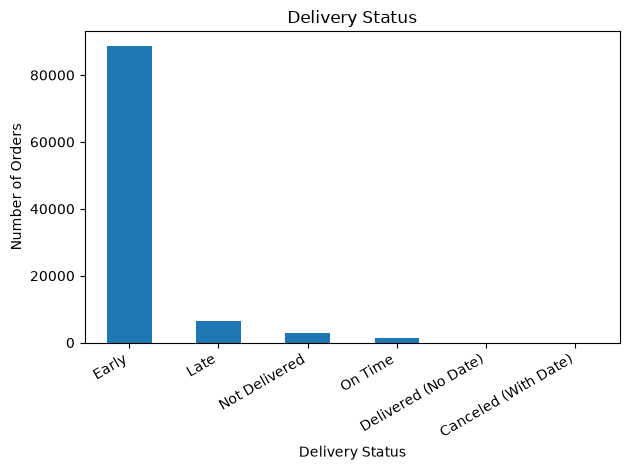

In [43]:
orders["delivery_status"].value_counts().plot(
    kind="bar"
)

plt.title("Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Chronological violations

In [44]:
# Find chronological violations (logical sequence is purchase -> approval -> shipped -> delivered)

# Check if any approved orders before purchase
impossible_approval = orders[orders['order_approved_at'] < orders['order_purchase_timestamp']]
# Check if any shipped orders before approval
impossible_shipping = orders[orders['order_delivered_carrier_date'] < orders['order_approved_at']]
# Time-Traveler" anomalies = delivery date is before the carrier delivery date, which is impossible
# Check if any delivered orders before shipped
impossible_delivery = orders[orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date']]

print(f"Approved before purchase: {len(impossible_approval)} rows")
print(f"Shipped before approval: {len(impossible_shipping)} rows")
print(f"Delivered before shipped (Time Travelers): {len(impossible_delivery)} rows")

Approved before purchase: 0 rows
Shipped before approval: 1359 rows
Delivered before shipped (Time Travelers): 23 rows


### Distribution of variance days (how many days early or late)

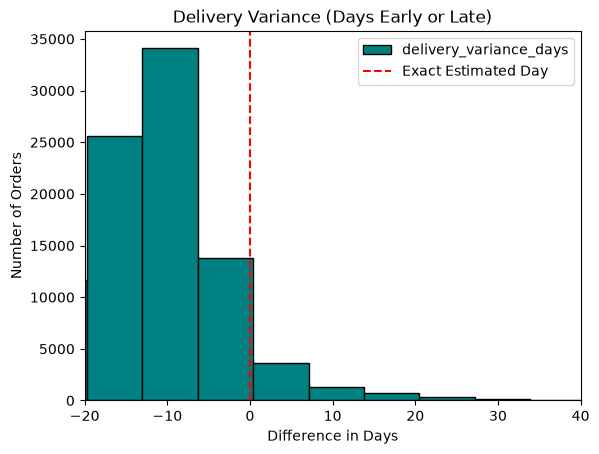

In [45]:
# Calculate how many calendar days early (-) or late (+) the order arrived
orders["delivery_variance_days"] = (
    orders["delivery_date"] -orders["estimated_delivery_date"]
).dt.days

# Keep valid completed deliveries for delivery-performance analysis
valid_deliveries = (
    (orders["order_status"] == "delivered") &
    (orders["delivery_date"].notna()) &
    (orders["estimated_delivery_date"].notna())
)

# Plot delivery variance only for valid delivered orders
# positive = late, 0 = on time, negative = early
orders.loc[valid_deliveries, "delivery_variance_days"].plot(
    kind="hist",
    bins=50,
    color="teal",
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--", label="Exact Estimated Day")
plt.title("Delivery Variance (Days Early or Late)")
plt.xlabel("Difference in Days")
plt.ylabel("Number of Orders")
plt.legend()
plt.xlim(-20, 40)   # Limit chart range, Show delivery differences from 20 days late to 40 days early
plt.show()

In [46]:
# Turns floats into integers, but leaves blanks as <NA> instead of crashing
orders['delivery_variance_days'] = orders['delivery_variance_days'].astype('Int64')
print("Current data type:", orders['delivery_variance_days'].dtype)
print(orders['delivery_variance_days'])

Current data type: Int64
0         -8
1         -6
2        -18
3        -13
4        -10
        ... 
99436    -11
99437     -2
99438     -6
99439    -21
99440    -18
Name: delivery_variance_days, Length: 99441, dtype: Int64


# Order_items

## Load the dataset

In [47]:
# order_items tells us what products were included in each order
# 1 order_id may appear multiple times in order_items because can have multiple products in 1 order

import pandas as pd
order_items = pd.read_csv(r"D:\Users\User\Documents\Project_1\Data\olist_order_items_dataset.csv")

## Overall view of data

In [48]:
print(order_items.info())

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB
None


In [49]:
print(order_items.head())

                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-15 10:10:18   12.99          12.7

## Check for duplicates

In [50]:
# Check duplicate rows
order_items.duplicated().sum()

np.int64(0)

In [51]:
# Check for duplicates in id column
# Should have many duplicates because 1 order can have multiple products
order_items['order_id'].duplicated().sum()

np.int64(13984)

In [52]:
order_items['order_id'].nunique()

98666

In [53]:
# Check if every combination of order_id and order_item_id is unique
# Error if there is duplicate
# subset = only look at these columns instead of the entire row
order_items.duplicated(subset=['order_id','order_item_id']).sum()

np.int64(0)

## Check for missing values

In [54]:
# Check missing values
order_items.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

## Check price and freight value

In [55]:
# Check the numerical columns
order_items[['price','freight_value']].describe()

# High right skews (outliers) exist
# Median (50%) price is 74.99 BRL, but max price is all the way to 6735 BRL.
# Mean is much higher than median, means there is a few incredibly expensive items dragging the mean up.
# Median shipping cost is 16.26 BRL, but the max is 409.68 BRL. Most packages are cheap to ship but a few heavy, bulky or long-distance orders cost a lot to deliver.
# 25% (25th percentile) means 25% of all the products cost 39.90 BRL or less and 25% of all deliveries cost 13.08 BRL or less.
# E.g. item price = 39.90, shipping cost = 13.08, total payment = 52.98, shipping proportion = 13.08/52.98 = 24.7%
# Means the shipping cost take up around 25% of the total money a customer has to pay
# Cause 'cart abandonement' because shipping cost is so high compared to the relatively cheap price of the product, customer frustrated so don't buy
# Customer doesn't want to pay too much for their delivery, hurt sales

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [56]:
# Check if there are zero or negative prices
(order_items['price'] <= 0).sum()

np.int64(0)

In [57]:
# Check if there are zero or negative shipping cost
# Shipping cost can be 0 due to free shipping promotions, pickup, digital products, bundled items (only first item has shipping cost, rest in the same order do not)
# there are 383 rows with 0 shipping cost
(order_items['freight_value'] < 0).sum()

np.int64(0)

In [58]:
(order_items['freight_value'] == 0).sum()

np.int64(383)

## Strings to datetime conversion

In [59]:
# Change dates from strings format to dates
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  str           
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  str           
 3   seller_id            112650 non-null  str           
 4   shipping_limit_date  112650 non-null  datetime64[us]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 6.0 MB


## EDA

### Check number of items

### Total number of items sold

In [60]:
# Total number of items sold
total_items = len(order_items)
print(total_items)

112650


### Distribution of price

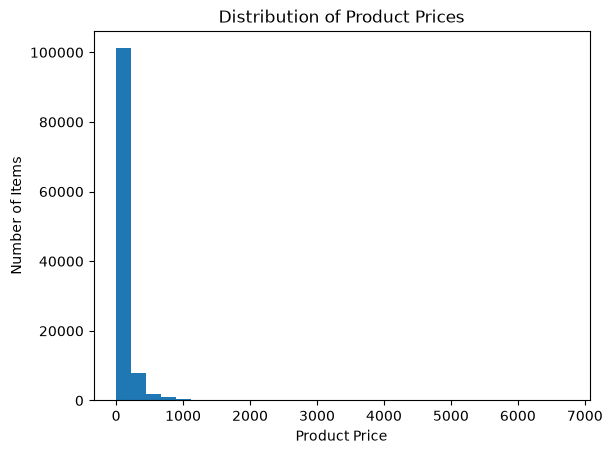

In [61]:
# Explore price
order_items["price"].plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Product Prices")
plt.xlabel("Product Price")
plt.ylabel("Number of Items")

# Zoom into the most active price range
#plt.xlim(0, 1000)

plt.show()

# right-skewed distribution
# Vast majority of items are highly affordable (between 0 and 250 BRL)
# Transactions become very rare as the price increases
# There's a few extreme price outliers

### Distribution of freight value/shipping cost

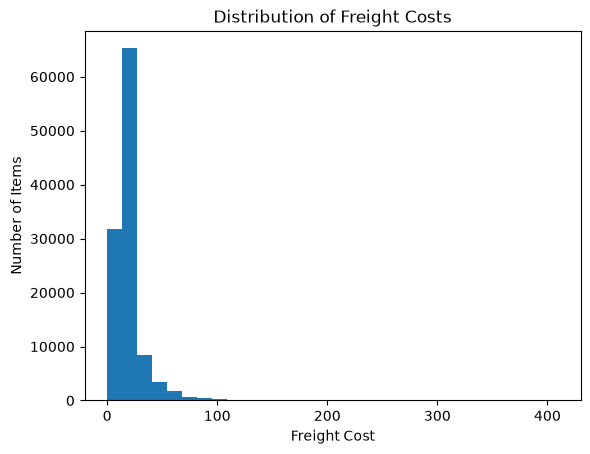

In [62]:
# Explore shipping fees
order_items["freight_value"].plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Freight Costs")
plt.xlabel("Freight Cost")
plt.ylabel("Number of Items")

# Zoom in
#plt.xlim(0, 200)

plt.show()

# Most shipping is cheap and predictable
# Under 15 BRL shows that there are a lot of nearby deliveries (low cost)
# super expensive shipping is incredibly rare (e.g. heavy things or sending to remote areas)
# since shipping mostly costs less than 30 BRL, company can offer deals like 'free shipping when you spend 150 BRL'
# company won't lose money because the actual shipping cost they have to pay for the customer is small and stable

### Relationship between price and shipping cost

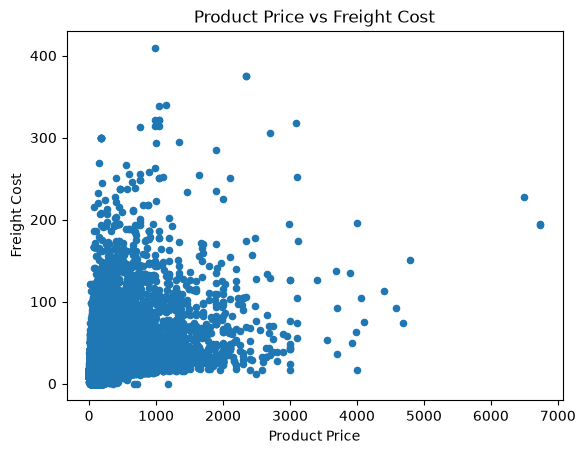

In [63]:
# Investigate the relationship between product price and shipping cost
# See whether more expensive products have higher shipping costs, and whether cheaper products have lower shipping costs

order_items.plot(
    kind="scatter",
    x="price",
    y="freight_value"
)

plt.title("Product Price vs Freight Cost")
plt.xlabel("Product Price")
plt.ylabel("Freight Cost")
plt.show()

In [64]:
# One small improvement: because Olist has some products with very different prices/freight values, the plot may become crowded.
# You could later calculate a correlation as a numerical follow-up:

order_items[['price', 'freight_value']].corr()

,price,freight_value
price,1.000000,0.414204
freight_value,0.414204,1.000000


# Python to PostgreSQL

In [70]:
%pip install sqlalchemy psycopg2-binary

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [71]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_date,delivery_date,days_to_deliver,estimated_delivery_date,days_to_estimate_delivery,delivery_status,purchase_month,delivery_variance_days,carrier_pickup_day
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10-10,8,2017-10-18,16,Early,2017-10,-8,2
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-08-07,14,2018-08-13,20,Early,2018-07,-6,3
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08-17,9,2018-09-04,27,Early,2018-08,-18,2
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11-18,2017-12-02,14,2017-12-15,27,Early,2017-11,-13,2
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02-16,3,2018-02-26,13,Early,2018-02,-10,2


In [ ]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sqlalchemy.types import VARCHAR, Integer, DateTime, Numeric

# 1. FIX THE ERROR: Convert Period to standard Timestamp
#orders["purchase_month"] = orders["purchase_month"].dt.to_timestamp()

username = "postgres"
password = "Dach@1208"
host = "localhost"
port = "5432"
database = "olist_ecommerce"

url = URL.create(
    drivername="postgresql+psycopg2",
    username=username,
    password=password,
    host=host,
    port=int(port),
    database=database
)

engine = create_engine(url)

# Upload the two DataFrames
orders.to_sql(
    "orders",
    engine,
    if_exists="replace",
    index=False,
    dtype={
        # Text/IDs
        "order_id": VARCHAR(50),
        "customer_id": VARCHAR(50),
        "order_status": VARCHAR(30),
        "delivery_status": VARCHAR(30),

        # Date & Times
        "order_purchase_timestamp": DateTime,
        "order_approved_at": DateTime,
        "order_delivered_carrier_date": DateTime,
        "order_delivered_customer_date": DateTime,
        "order_estimated_delivery_date": DateTime,
        "purchase_date": DateTime,
        "delivery_date": DateTime,
        "estimated_delivery_date": DateTime,
        "purchase_month": DateTime,  # Forces Postgres to explicitly set it as TIMESTAMP

        # Performance/Numbers
        "days_to_deliver": Integer,
        "days_to_estimate_delivery": Integer,
        "delivery_variance_days": Integer,
        "carrier_pickup_day": Integer
    }
)


order_items.to_sql(
    "order_items",
    engine,
    if_exists="replace",
    index=False,
    dtype={
        # Text/ID Columns
        "order_id": VARCHAR(50),            # Highly efficient for database indexing
        "product_id": VARCHAR(50),          # Keeps standard product code limits
        "seller_id": VARCHAR(50),           # Restricts length to prevent bloated table scans

        # Whole Numbers
        "order_item_id": Integer,           # Perfect for small sequence numbers (1, 2, 3...)

        # Dates & Times
        "shipping_limit_date": DateTime,    # Maps perfectly to PostgreSQL TIMESTAMP

        # Financial / Decimal Data
        "price": Numeric(10, 2),            # Ensures exact monetary precision without rounding bugs
        "freight_value": Numeric(10, 2)     # Handles shipping costs accurately up to 99,999,999.99
    }
)

print("Both tables successfully uploaded to PostgreSQL.")